In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'num'
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

df = pd.read_csv(
    url,
    names=columns,
    na_values='?'
)

# Перетворюємо всі значення на числові
df = df.apply(pd.to_numeric, errors='coerce')

# Видаляємо рядки з пропущеними значеннями
df = df.dropna()

print("Розмір датасету:", df.shape)
print("\nПерші 5 рядків:")
print(df.head())


Розмір датасету: (297, 14)

Перші 5 рядків:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0   3.0    0  
4    1.0  0.0   3.0    0  


In [3]:
X = df.drop('num', axis=1)

# Цільова змінна:
# 0 - відсутність хвороби
# 1 - наявність хвороби
y = (df['num'] > 0).astype(int)

print("\nРозподіл класів:")
print(y.value_counts())


Розподіл класів:
num
0    160
1    137
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [5]:
X_train = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_test = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_train = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)


In [6]:
input_size = X_train.shape[1]

model = nn.Sequential(
    nn.Linear(input_size, 16),
    nn.ReLU(),

    nn.Linear(16, 8),
    nn.ReLU(),

    nn.Linear(8, 1),
    nn.Sigmoid()
)

print("\nАрхітектура нейромережі:")
print(model)

criterion = nn.BCELoss()

# Оптимізатор Adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Кількість епох
epochs = 30

# Списки для збереження результатів
train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        # Обнуляємо градієнти
        optimizer.zero_grad()

        # Пряме поширення
        outputs = model(inputs)

        # Обчислення помилки
        loss = criterion(outputs, labels)

        # Зворотне поширення
        loss.backward()

        # Оновлення ваг
        optimizer.step()

        # Накопичення втрат
        running_loss += loss.item() * inputs.size(0)

        # Перетворення ймовірностей у класи
        predictions = (outputs >= 0.5).float()

        # Підрахунок правильних прогнозів
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    # Середня втрата за епоху
    epoch_loss = running_loss / total

    # Точність за епоху
    epoch_accuracy = correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    # Виведення результатів
    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy * 100:.2f}%"
    )


Архітектура нейромережі:
Sequential(
  (0): Linear(in_features=13, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)
Epoch [1/30] | Loss: 0.6845 | Accuracy: 58.23%
Epoch [2/30] | Loss: 0.6775 | Accuracy: 61.18%
Epoch [3/30] | Loss: 0.6702 | Accuracy: 65.82%
Epoch [4/30] | Loss: 0.6621 | Accuracy: 67.93%
Epoch [5/30] | Loss: 0.6532 | Accuracy: 73.42%
Epoch [6/30] | Loss: 0.6430 | Accuracy: 75.11%
Epoch [7/30] | Loss: 0.6319 | Accuracy: 75.53%
Epoch [8/30] | Loss: 0.6193 | Accuracy: 77.64%
Epoch [9/30] | Loss: 0.6051 | Accuracy: 79.32%
Epoch [10/30] | Loss: 0.5898 | Accuracy: 81.01%
Epoch [11/30] | Loss: 0.5732 | Accuracy: 80.59%
Epoch [12/30] | Loss: 0.5560 | Accuracy: 80.59%
Epoch [13/30] | Loss: 0.5372 | Accuracy: 81.01%
Epoch [14/30] | Loss: 0.5188 | Accuracy: 81.86%
Epoch [15/30] | Loss: 0.5009 | Accuracy: 82.70%
Epoch [16/30] | Loss: 0.4822 | Ac

In [8]:
results = pd.DataFrame({
    "Метрика": ["Loss", "Accuracy"],
    "Значення": [
        round(train_losses[-1], 4),
        f"{train_accuracies[-1] * 100:.2f}%"
    ]
})

print(results.to_string(index=False))


model.eval()

with torch.no_grad():

    test_outputs = model(X_test)

    test_predictions = (test_outputs >= 0.5).float()

    test_loss = criterion(test_outputs, y_test).item()

    test_accuracy = (
        (test_predictions == y_test)
        .float()
        .mean()
        .item()
    )


print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


 Метрика Значення
    Loss    0.358
Accuracy   85.65%
Test Loss: 0.3131
Test Accuracy: 86.67%


In [ ]:
#  Task 4

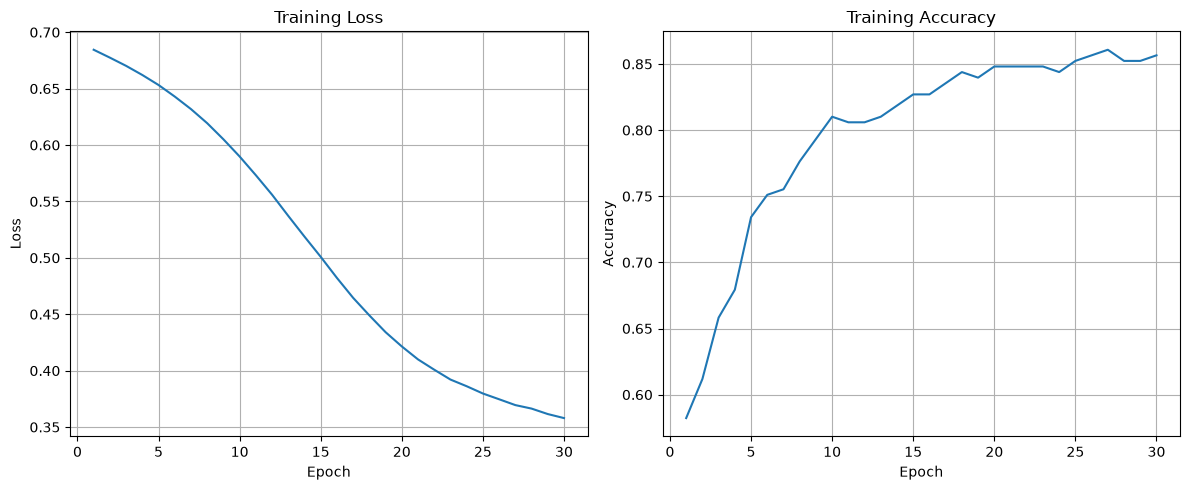

In [9]:
plt.figure(figsize=(12, 5))

# Графік Loss
plt.subplot(1, 2, 1)

plt.plot(range(1, epochs + 1), train_losses)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()

# Графік Accuracy
plt.subplot(1, 2, 2)

plt.plot(range(1, epochs + 1), train_accuracies)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()

plt.tight_layout()

plt.savefig(
    "mlp_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()